## What is LangChain? 

Langchain is a framework that helps developers build applications using Large Language Models (LLMs). A large language model is a type of artificial intelligence that is trained on enourmous amounts of text data to understand and generate human-like responses. Some common examples include GPT-4 and GPT-3.5. What LangChain does is that it allows the LLM's to connect with external tools, databases, API's and databses so it can do more than just answer questions from its memory, it can answer questions based off given sources. 

### Loading Our API Key

We will load our OpenAI API key here. For different OpenAI model APIs, you can visit https://platform.openai.com/docs/models?utm_source=chatgpt.com

In [6]:
import os
from dotenv import load_dotenv

load_dotenv()   # loads our .env file

openai_api_key = os.getenv("OPENAI_API_KEY")

print("API Key loaded:", bool(openai_api_key))

API Key loaded: True


### Loading our LLM

In [7]:
from langchain_openai import OpenAI

llm = OpenAI(temperature=.67)    # Temperature means how creative/risky you want the model to be
question = llm.invoke("What is the capital of Canada?")
print(question)



The capital of Canada is Ottawa.


### Let's create a function that prompts the user 

In [8]:
from langchain_core.prompts import PromptTemplate

def restaurant_name_generator():

    cuisine = input("Enter a type of cuisine: ")

    # Create a reusable prompt template
    prompt = PromptTemplate(
        input_variables=["cuisine"],
        template="I want to open a restaurant for {cuisine} food. Suggest 3 fancy names."
    )

    # Create a chain that connects prompt to LLM
    chain = prompt | llm
    response = chain.invoke({"cuisine": cuisine})
    print(response)


In [9]:
restaurant_name_generator()



1. "Persian Palace"
2. "Saffron Spice"
3. "Taste of Tehran"


# Retreival Augmented Generation (RAG) 
RAG is the most commonly used application of LangChain and LLMs. It is the AI method that combines searching given data and produces accurate, context-aware responses.

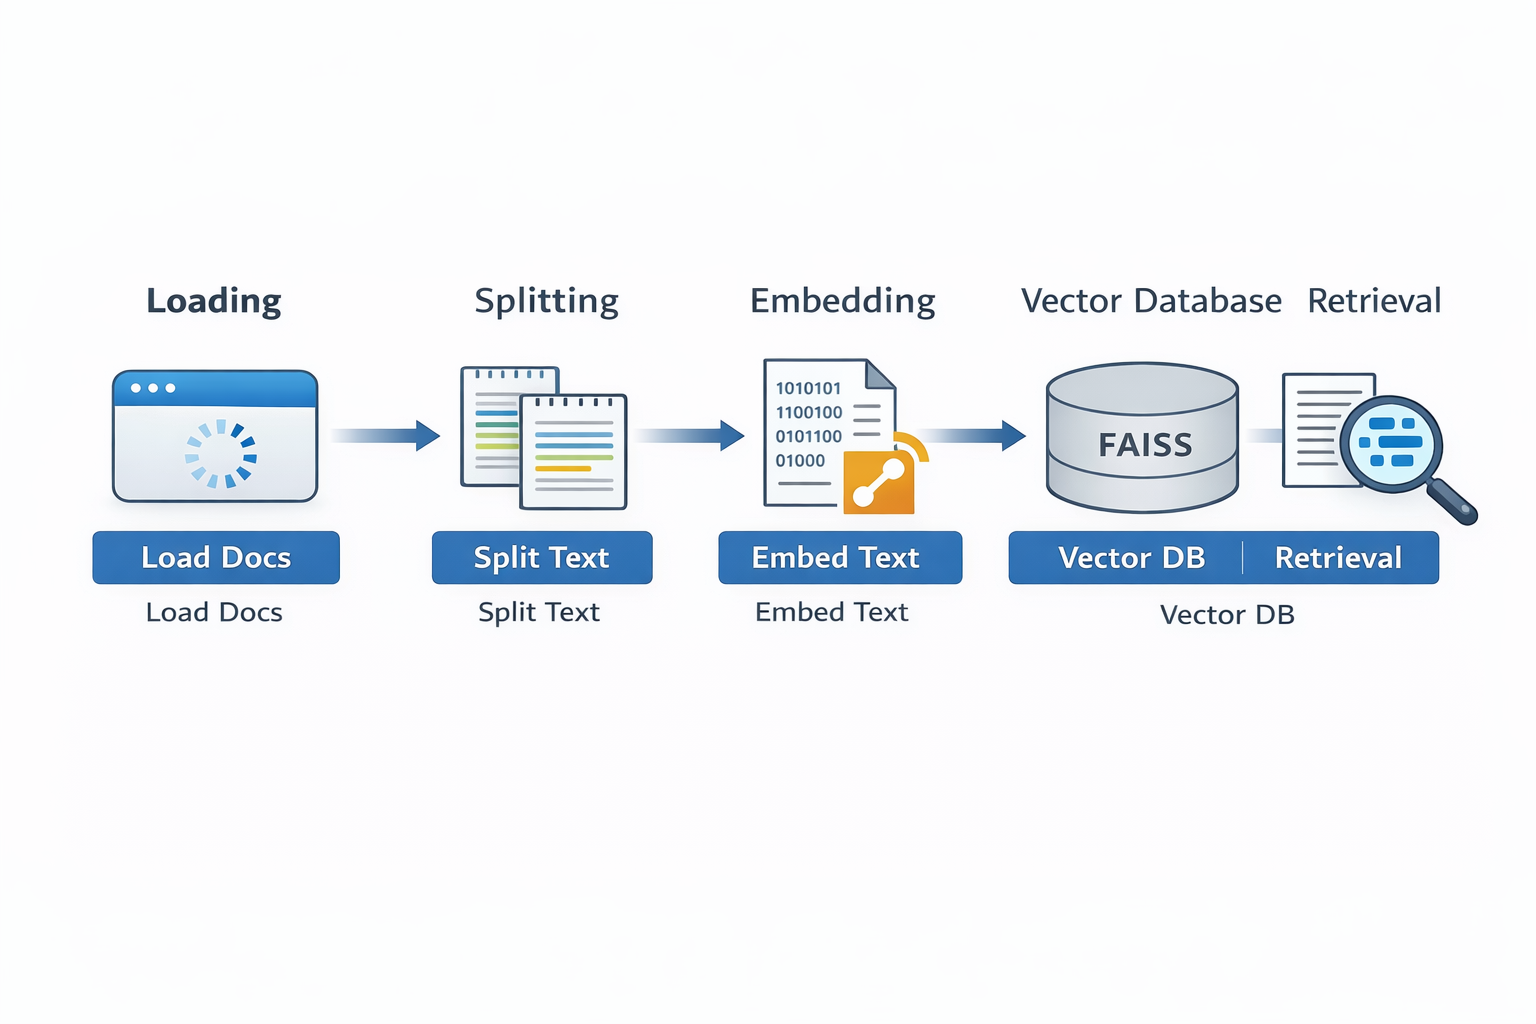

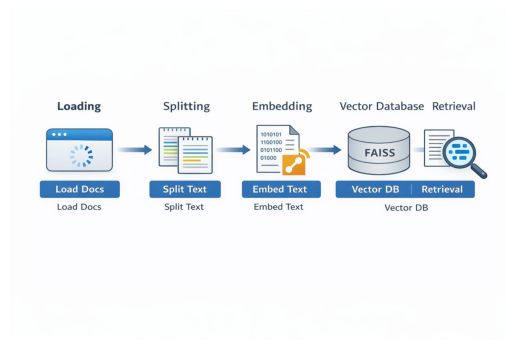

In [10]:
# save this as show_image.py
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(r"C:\Users\Shervin Zare\Downloads\RAG pipeline image.png")
plt.imshow(img)
plt.axis("off")
plt.show()

## Document Loading
Data Loading in langchain is the process of loading data from various sources like files, databases, web pages, etc. The data is loaded into a Document object which is a part of the langchain library. The Document object contains the text content of the data and metadata like the source URL, title, etc. The Document object is then used for further processing like text analysis, summarization, etc.

In [11]:
## Web page loading

from langchain_community.document_loaders import WebBaseLoader

loader = WebBaseLoader("https://www.govinfo.gov/content/pkg/CDOC-110hdoc50/html/CDOC-110hdoc50.htm")
documents = loader.load()
print(documents)

USER_AGENT environment variable not set, consider setting it to identify your requests.


[Document(metadata={'source': 'https://www.govinfo.gov/content/pkg/CDOC-110hdoc50/html/CDOC-110hdoc50.htm', 'language': 'No language found.'}, page_content="\n[House Document 110-50]\n[From the U.S. Government Publishing Office]\n\n\n\n110th Congress                                               Document\n\n                        HOUSE OF REPRESENTATIVES\n1st Session                                                No. 110-50\n\n \n                                   THE\n                              CONSTITUTION\n                                 OF THE\n                              UNITED STATES\n                               OF AMERICA\n\n                               As Amended\n\n------------------------------------------------------------------------\n\n                          Unratified Amendments\n\n------------------------------------------------------------------------\n\n                            Analytical Index\n\n\n\n\n                         PRESENTED BY MR. BRADY\

In [12]:
## CSV File loading 

from langchain_community.document_loaders.csv_loader import CSVLoader

loader2 = CSVLoader(file_path="Air_Quality.csv", content_columns=["Name"])
documents2 = loader2.load()
len(documents)

1

In [13]:
from langchain_community.document_loaders import PyPDFLoader

loader3 = PyPDFLoader("moby dick.pdf")
documents3 = loader3.load()

print("number of pages: ", len(documents3))

# Print first page
print("First page:")
print(documents3[0].page_content)

number of pages:  468
First page:
HERMAN MELVILLE
MOBYDICK


## Document Splitting

The `separators` argument `["\n\n", "\n"]` tells the splitter **where to try to break the text**:

- `\n\n` → split at **paragraph breaks** first.  
- `\n` → if no paragraph break is found, split at **single line breaks**.  

This way, the text is split at natural boundaries instead of in the middle of sentences whenever possible.


In [14]:
%pip install -qU langchain-text-splitters

from langchain_text_splitters import RecursiveCharacterTextSplitter

# Split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    separators=["\n\n", "\n"]
)


chunks = text_splitter.split_documents(documents)

# Print only the first chunk
first_chunk = chunks[0]
print(f"Chunk 0 size: {len(first_chunk.page_content)}")
print(first_chunk.page_content)


Note: you may need to restart the kernel to use updated packages.
Chunk 0 size: 916
[House Document 110-50]
[From the U.S. Government Publishing Office]



110th Congress                                               Document

                        HOUSE OF REPRESENTATIVES
1st Session                                                No. 110-50

 
                                   THE
                              CONSTITUTION
                                 OF THE
                              UNITED STATES
                               OF AMERICA

                               As Amended

------------------------------------------------------------------------

                          Unratified Amendments

------------------------------------------------------------------------

                            Analytical Index




                         PRESENTED BY MR. BRADY

                             OF PENNSYLVANIA

               July 25, 2007        Ordered to be printed


[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Vector Databases & Embeddings
A vector database stores embeddings, which are numerical representations of data that capture its meaning or features. Embeddings work by converting text, images, or other data into high-dimensional vectors using a machine learning model, so similar items have vectors close together in space. This allows the database to perform fast similarity searches, enabling AI systems like in RAG to retrieve relevant information efficiently for language models to generate answers.

In [15]:
%pip install -qU langchain-community langchain-huggingface

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
# Import the HuggingFace embeddings class
from langchain_huggingface import HuggingFaceEmbeddings

# We will use a HuggingFace embedding model to create the embeddings object
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")  

In [17]:
# Import FAISS class from vectorstore library
from langchain_community.vectorstores import InMemoryVectorStore

# Create the FAISS vector database
vectorstore = InMemoryVectorStore.from_documents(chunks, embeddings)

# The from_documents method returns the store, but you can check the length of the input
print(f"Number of chunks indexed: {len(chunks)}")

Number of chunks indexed: 430


## Retrieval

Now that we understand the indexing pipeline, we can 
utilize our vector database to retrieve relevant documents
for a given query.

In [18]:
def retrieve(vector_database):
    # Get user input
    question = input("What is your question? ")

    # Search the vector store directly
    docs = vector_database.similarity_search(question, k=1)  # Top 1 result

    # Print the results
    for doc in docs:
        print(doc.page_content[:500])
        print("-" * 100 + "\n")


In [ ]:
retrieve(vectorstore)

Section 1. No person shall be elected to the office of the 
President more than twice, and no person who has held the 
office of President, or acted as President, for more than two 
years of a term of which some other person was elected 
President shall be elected to the office of the President more 
than once. But this Article shall not apply to any person 
holding the office of President when this Article was proposed 
by the Congress, and shall not prevent any person who may be 
holding the o
----------------------------------------------------------------------------------------------------



In [2]:
from pypdf import PdfReader, PdfWriter

def remove_last_two_pages(input_path, output_path):
    reader = PdfReader(input_path)
    writer = PdfWriter()

    total_pages = len(reader.pages)

    # Add all pages except the last two
    for page in reader.pages[:total_pages-2]:
        writer.add_page(page)

    # Save the new PDF
    with open(output_path, "wb") as f:
        writer.write(f)

remove_last_two_pages(
    r"C:\Users\Shervin Zare\Downloads\Shervin's Metrolinx Resume.pdf",
    r"C:\Users\Shervin Zare\Downloads\Shervin's Metrolinx Resume Final.pdf"
)